In [15]:
!pip install numpy matplotlib seaborn kagglehub pandas scikit-learn


[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:
import pandas as pd
import re

# 1. Đọc dữ liệu
df = pd.read_csv('camera-digital-dataset.csv') # Thay tên file cho đúng với file bạn tải về

# 2. Làm sạch cột Price (Quan trọng nhất)
# Loại bỏ chữ 'Rp', dấu phẩy, và chuyển về kiểu số (float)
def clean_price(price_str):
    if isinstance(price_str, str):
        # Giữ lại số và dấu chấm thập phân, xóa hết ký tự khác
        price_str = re.sub(r'[^\d.]', '', price_str.replace(',', ''))
        return float(price_str)
    return price_str

df['price_cleaned'] = df['price'].apply(clean_price)

# 3. Trích xuất tên hãng (Brand) từ cột camera_name
# Giả sử tên hãng luôn nằm ở từ đầu tiên của tên máy
df['brand'] = df['camera_name'].apply(lambda x: x.split(' ')[0])

# 4. Xử lý các cột thông số (ví dụ: Pixel)
# Giả sử cột 'pixel' có dạng "24 MP", ta cần tách lấy số 24
def clean_pixel(pixel_str):
    if isinstance(pixel_str, str):
        numbers = re.findall(r'\d+', pixel_str)
        return float(numbers[0]) if numbers else 0
    return pixel_str

df['pixel_cleaned'] = df['pixel'].apply(clean_pixel)

# 5. Xử lý dữ liệu khuyết thiếu (Missing values)
# Điền giá trị trung bình cho các cột số
df.fillna(df.mean(numeric_only=True), inplace=True)

# Xem kết quả sau khi làm sạch
print(df[['camera_name', 'brand', 'price_cleaned', 'pixel_cleaned']].head())

# Lưu lại file đã sạch để dùng cho mô hình AI
df.to_csv('camera_cleaned.csv', index=False)

         camera_name     brand  price_cleaned  pixel_cleaned
0      Fujifilm X-M5  Fujifilm     15499000.0           26.1
1     Sony ZV-E10 II      Sony     18999000.0           26.0
2   Ricoh GR III HDF     Ricoh     19599000.0           24.0
3  Ricoh GR IIIx HDF     Ricoh     20989000.0           24.0
4         Sony a6700      Sony     22999000.0           26.0


In [17]:
import pandas as pd
import re

# Đọc dữ liệu
df1 = pd.read_csv('camera-digital-dataset.csv', encoding='utf-8')
df2 = pd.read_csv('amazon-cameras.csv', encoding='utf-8')

# Làm sạch file thông số
df1['price'] = df1['price'].astype(str).str.replace('Rp', '').str.replace(',', '').str.extract(r'(\d+)').astype(float)
df1['screen_dots'] = df1['screen_dots'].astype(str).str.replace(',', '').astype(float)
df1['brand'] = df1['camera_name'].str.split().str[0]
df1['model_key'] = df1['camera_name'].str.lower().str.replace(r'[^\w\s]', '', regex=True)

# Làm sạch file Amazon
df2['price'] = df2['price'].astype(str).str.replace('SAR', '').str.replace(',', '').astype(float)
df2['rating'] = pd.to_numeric(df2['rating'], errors='coerce')
# Xử lý review_count: thay 'No Reviews' bằng NaN, sau đó ép số
df2['review_count'] = df2['review_count'].astype(str).str.replace(',', '')
df2['review_count'] = df2['review_count'].replace('No Reviews', pd.NA)
df2['review_count'] = pd.to_numeric(df2['review_count'], errors='coerce')
df2['brand'] = df2['brand'].fillna(df2['title'].str.split().str[0])
df2['model_key'] = df2['title'].str.lower().str.replace(r'[^\w\s]', '', regex=True)

# Gộp dữ liệu
merged = pd.merge(df1, df2, on=['brand', 'model_key'], how='outer', suffixes=('_spec', '_amzn'))

# Lưu kết quả
merged.to_csv('merged_cameras.csv', index=False, encoding='utf-8-sig')

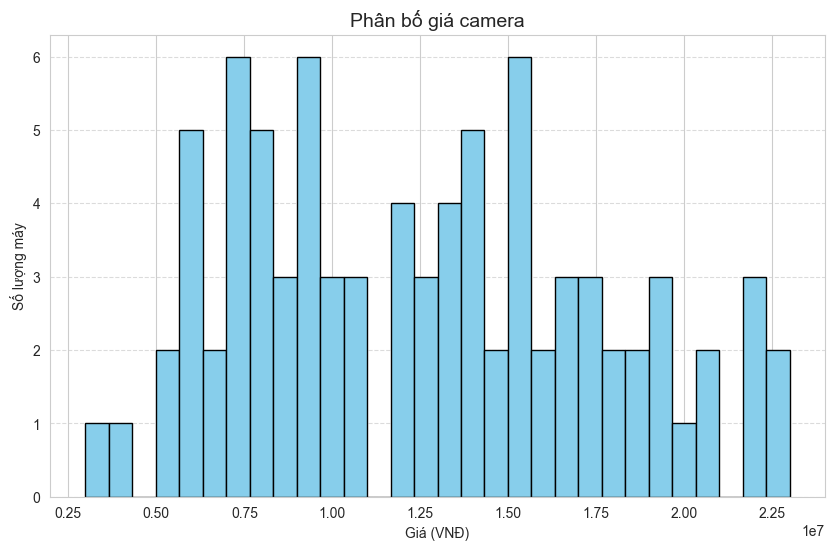

In [18]:
# Biểu đồ 1 (Histogram) - Phân bố giá camera
import pandas as pd
import matplotlib.pyplot as plt
import re

# Đọc dữ liệu
df = pd.read_csv('camera-digital-dataset.csv', encoding='utf-8')

# Làm sạch giá
def clean_price(price_str):
    if isinstance(price_str, str):
        price_str = re.sub(r'[^\d.]', '', price_str.replace(',', ''))
        return float(price_str)
    return price_str

df['price_cleaned'] = df['price'].apply(clean_price)

# Vẽ histogram
plt.figure(figsize=(10, 6))
df['price_cleaned'].dropna().hist(bins=30, color='skyblue', edgecolor='black')
plt.title('Phân bố giá camera', fontsize=14)
plt.xlabel('Giá (VNĐ)')
plt.ylabel('Số lượng máy')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

C:\Users\tthu5\AppData\Local\Temp\ipykernel_16432\1271401983.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=sensor_counts.values, y=sensor_counts.index, palette='Blues_r')


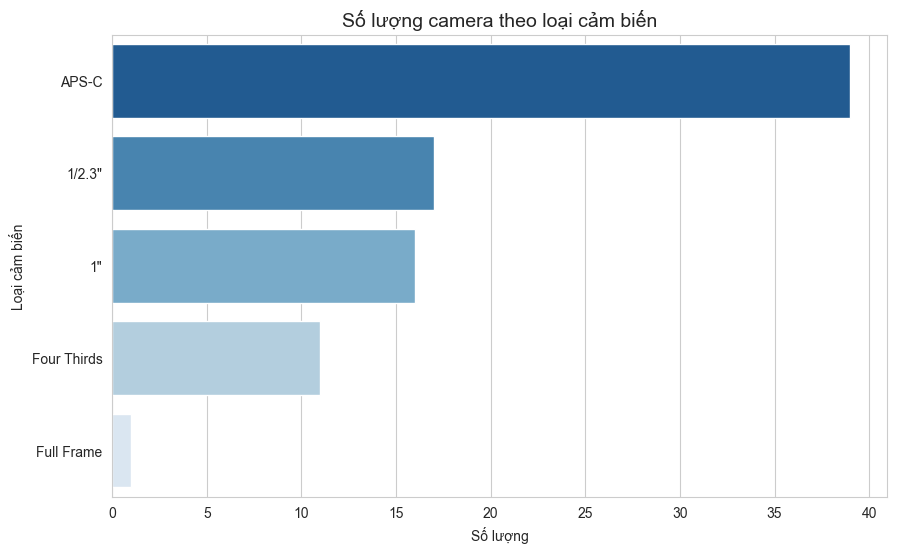

In [19]:
# Biểu đồ 2 (Bar-Chart) - Số lượng camera theo loại cảm biến
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('camera-digital-dataset.csv', encoding='utf-8')

# Đếm số lượng theo sensor_size
sensor_counts = df['sensor_size'].value_counts()

plt.figure(figsize=(10, 6))
sns.barplot(x=sensor_counts.values, y=sensor_counts.index, palette='Blues_r')
plt.title('Số lượng camera theo loại cảm biến', fontsize=14)
plt.xlabel('Số lượng')
plt.ylabel('Loại cảm biến')
plt.show()

C:\Users\tthu5\AppData\Local\Temp\ipykernel_16432\3602414812.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=stats, x='sensor_size', y='mean_weight', palette='Set2')


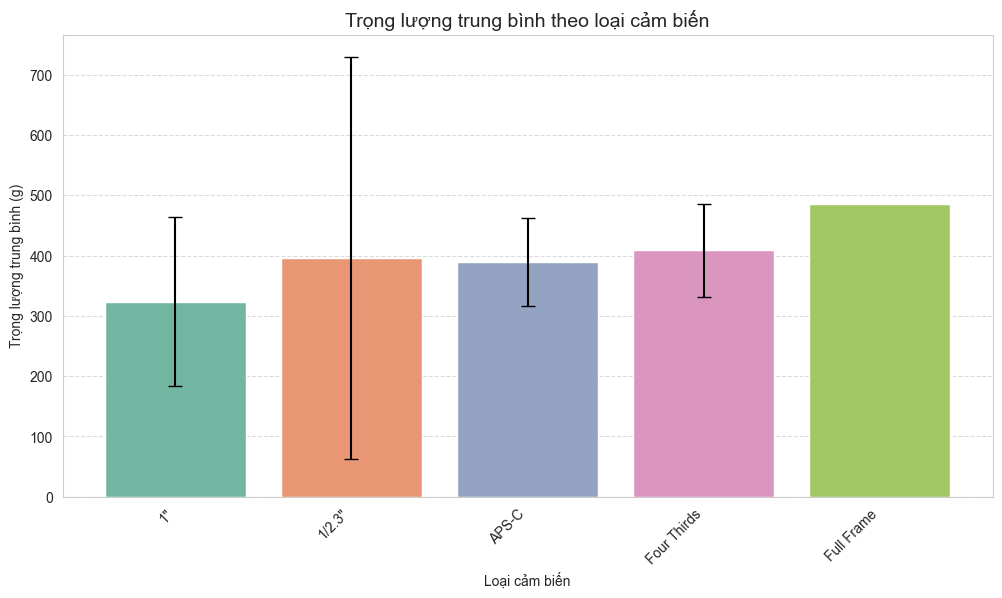

In [20]:
# Biểu đồ 3 (Box-Plot) - Phân bố trọng lượng theo loại cảm biến
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('camera_cleaned.csv', encoding='utf-8')

# Tính trung bình và độ lệch chuẩn theo sensor_size
stats = df.groupby('sensor_size')['weight'].agg(['mean', 'std']).reset_index()
stats.columns = ['sensor_size', 'mean_weight', 'std_weight']

# Vẽ bar chart với sai số
plt.figure(figsize=(12, 6))
sns.barplot(data=stats, x='sensor_size', y='mean_weight', palette='Set2')
plt.errorbar(x=range(len(stats)), y=stats['mean_weight'], 
             yerr=stats['std_weight'], fmt='none', c='black', capsize=5)
plt.title('Trọng lượng trung bình theo loại cảm biến', fontsize=14)
plt.xlabel('Loại cảm biến')
plt.ylabel('Trọng lượng trung bình (g)')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

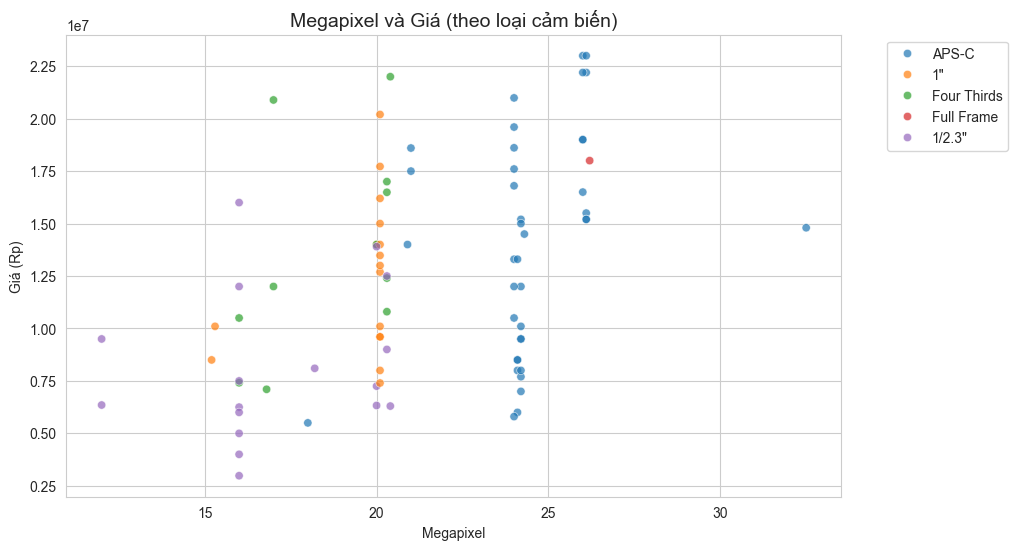

In [21]:
# Biểu đồ 4 (Scatter-Plot) - Mối quan hệ giữa Megapixel và Giá theo loại cảm biến
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('camera_cleaned.csv', encoding='utf-8')

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='pixel_cleaned', y='price_cleaned', hue='sensor_size', alpha=0.7)
plt.title('Megapixel và Giá (theo loại cảm biến)', fontsize=14)
plt.xlabel('Megapixel')
plt.ylabel('Giá (Rp)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

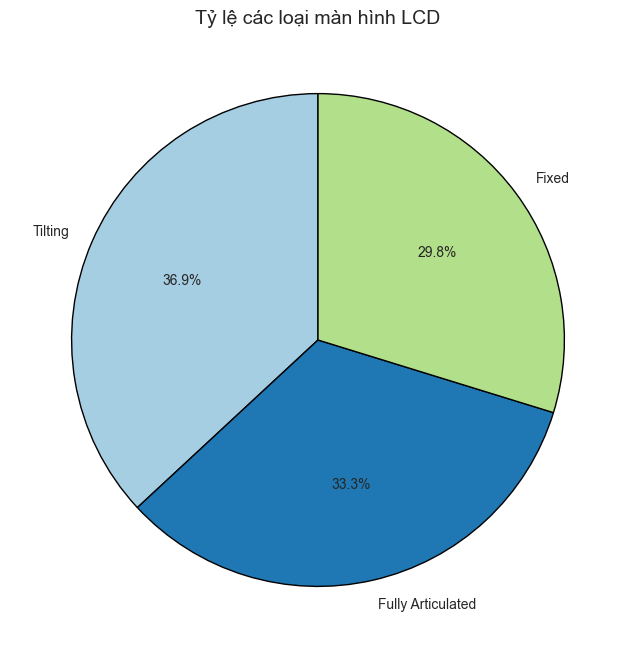

In [22]:
# Biểu đồ 5 (Pie-Chart) - Tỷ lệ các loại màn hình LCD
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('camera_cleaned.csv', encoding='utf-8')

lcd_counts = df['articulated_lcd'].value_counts()

plt.figure(figsize=(8, 8))
plt.pie(lcd_counts, labels=lcd_counts.index, autopct='%1.1f%%', startangle=90,
        colors=plt.cm.Paired.colors, wedgeprops={'edgecolor': 'black'})
plt.title('Tỷ lệ các loại màn hình LCD', fontsize=14)
plt.show()

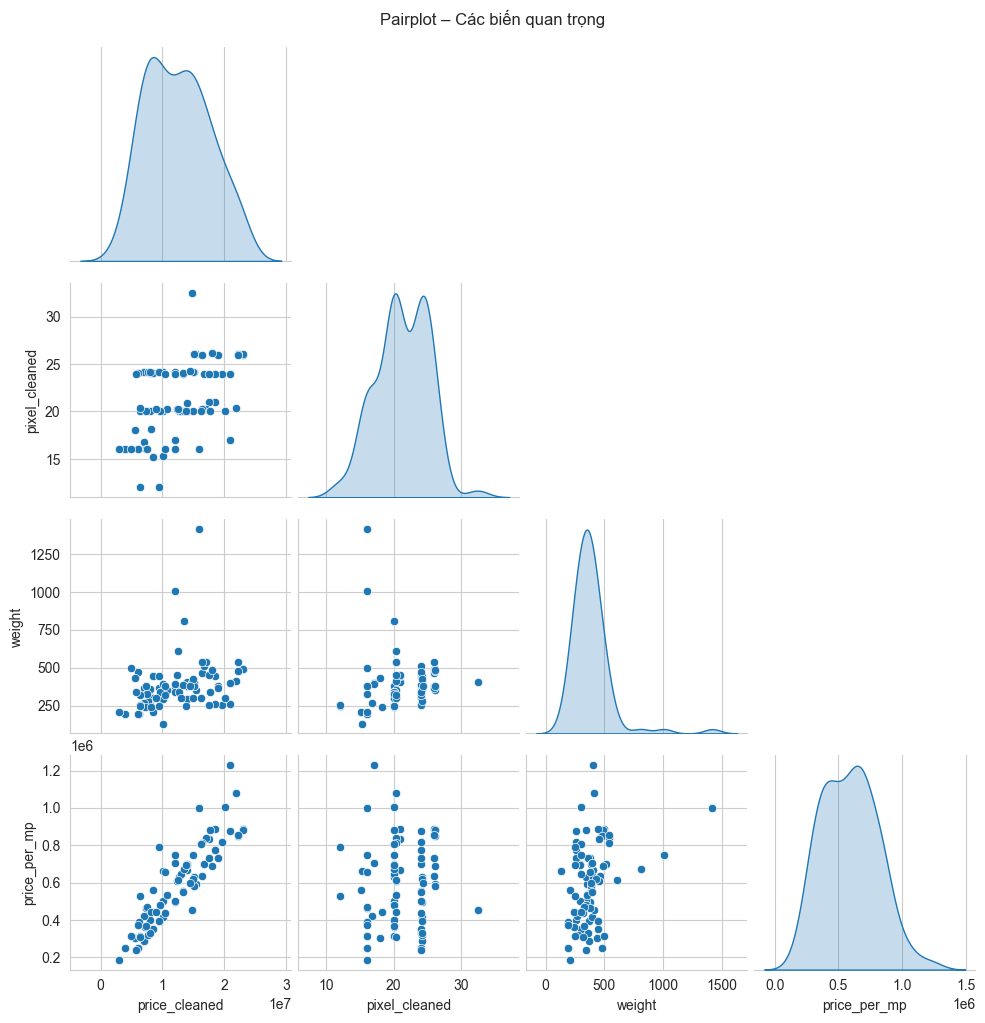

In [30]:
# Biểu đồ 6 (Pairplot) - Tương quan giữa các thông số kỹ thuật
sns.pairplot(df_clean[['price_cleaned', 'pixel_cleaned', 'weight', 'price_per_mp']].dropna(),
             diag_kind='kde', corner=True)
plt.suptitle('Pairplot – Các biến quan trọng', y=1.02)
plt.show()

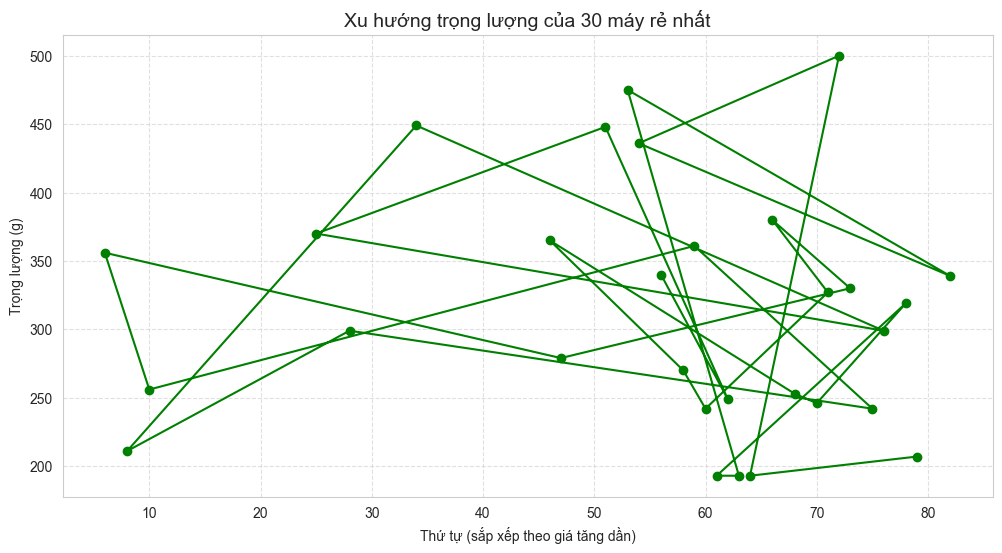

In [24]:
# Biểu đồ 7 (Line-Chart) - Xu hướng trọng lượng của 30 máy rẻ nhất
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('camera_cleaned.csv', encoding='utf-8')

data = df.sort_values('price_cleaned').head(30)
plt.figure(figsize=(12, 6))
plt.plot(data.index, data['weight'], marker='o', linestyle='-', color='green')
plt.title('Xu hướng trọng lượng của 30 máy rẻ nhất', fontsize=14)
plt.xlabel('Thứ tự (sắp xếp theo giá tăng dần)')
plt.ylabel('Trọng lượng (g)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

C:\Users\tthu5\AppData\Local\Temp\ipykernel_16432\3424976183.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=data, x='sensor_size', y='max_video_fps', palette='muted')


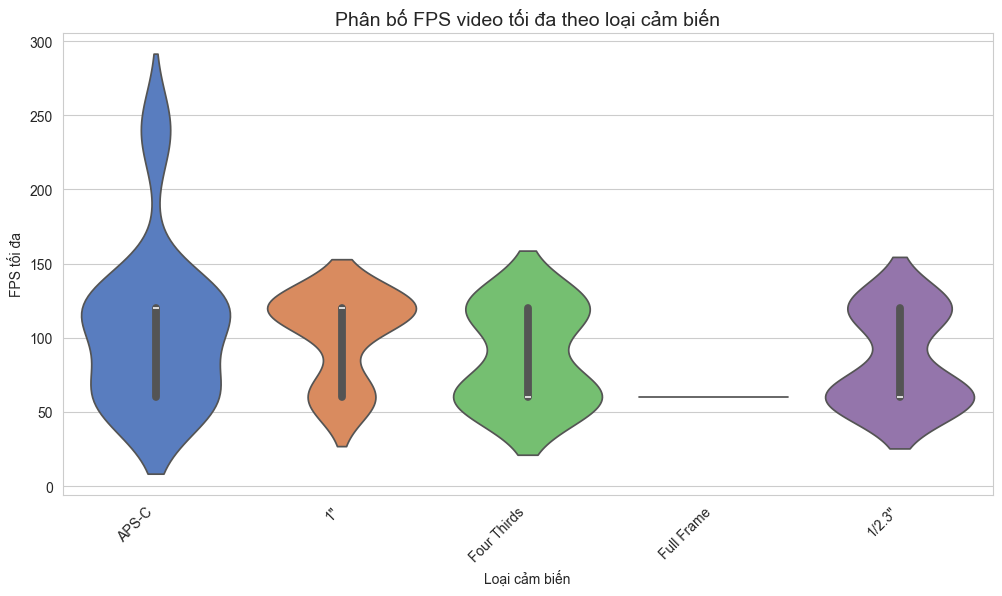

In [25]:
# Biểu đồ 8 (Violin-Plot) - Phân bố FPS video tối đa theo loại cảm biến
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('camera_cleaned.csv', encoding='utf-8')

data = df.dropna(subset=['max_video_fps', 'sensor_size'])

plt.figure(figsize=(12, 6))
sns.violinplot(data=data, x='sensor_size', y='max_video_fps', palette='muted')
plt.title('Phân bố FPS video tối đa theo loại cảm biến', fontsize=14)
plt.xlabel('Loại cảm biến')
plt.ylabel('FPS tối đa')
plt.xticks(rotation=45, ha='right')
plt.show()

In [26]:
# ----- Loại bỏ outlier bằng IQR -----
Q1 = df['price_cleaned'].quantile(0.25)
Q3 = df['price_cleaned'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df_clean = df[(df['price_cleaned'] >= lower) & (df['price_cleaned'] <= upper)]
print(f"Số dòng trước: {len(df)}, sau: {len(df_clean)}")

# ----- Feature Engineering đơn giản -----
df_clean['price_per_mp'] = df_clean['price_cleaned'] / df_clean['pixel_cleaned']
df_clean['weight_per_mp'] = df_clean['weight'] / df_clean['pixel_cleaned']

# Chọn features
features = ['pixel_cleaned', 'weight', 'max_video_fps', 'battery_life',
            'sensor_size', 'price_per_mp', 'weight_per_mp']
target = 'price_cleaned'
data = df_clean[features + [target]].copy()

Số dòng trước: 84, sau: 84


In [27]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import joblib

# Mã hóa sensor_size
le = LabelEncoder()
data['sensor_size_encoded'] = le.fit_transform(data['sensor_size'])
data = data.drop('sensor_size', axis=1)

# Chuẩn hóa
scaler = StandardScaler()
X = data.drop(target, axis=1)
y = data[target]
X_scaled = scaler.fit_transform(X)

# Chia train/test
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Huấn luyện
model = LinearRegression()
model.fit(X_train, y_train)

# Dự đoán
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

# Đánh giá
print("=== ĐÁNH GIÁ MÔ HÌNH ===")
print(f"R² train: {r2_score(y_train, y_pred_train):.4f}")
print(f"R² test : {r2_score(y_test, y_pred_test):.4f}")
print(f"RMSE train: {np.sqrt(mean_squared_error(y_train, y_pred_train)):,.0f} Rp")
print(f"RMSE test : {np.sqrt(mean_squared_error(y_test, y_pred_test)):,.0f} Rp")
print(f"MAE test  : {mean_absolute_error(y_test, y_pred_test):,.0f} Rp")

# Cross-validation
cv_scores = cross_val_score(model, X_scaled, y, cv=5, scoring='r2')
print(f"Cross-validation R² (5-fold): {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

# Lưu model
joblib.dump(model, 'camera_price_model.joblib')
joblib.dump(scaler, 'scaler.joblib')
joblib.dump(le, 'sensor_encoder.joblib')
with open('feature_names.txt', 'w') as f:
    f.write('\n'.join(X.columns))
print("\nĐã lưu model, scaler, encoder và feature names.")

=== ĐÁNH GIÁ MÔ HÌNH ===
R² train: 0.9803
R² test : 0.9838
RMSE train: 717,933 Rp
RMSE test : 599,756 Rp
MAE test  : 442,176 Rp
Cross-validation R² (5-fold): 0.9442 (+/- 0.0228)

Đã lưu model, scaler, encoder và feature names.


In [29]:
def predict_price(pixel, weight, max_fps, battery, sensor_size):
    # Tạo input với đúng thứ tự feature
    input_df = pd.DataFrame([[
        pixel, weight, max_fps, battery,
        pixel / weight,          # price_per_mp (ước lượng)
        weight / pixel,          # weight_per_mp
        le.transform([sensor_size])[0]
    ]], columns=X.columns)
    input_scaled = scaler.transform(input_df)
    return model.predict(input_scaled)[0]

# Ví dụ
print(f"Giá dự đoán: {predict_price(24, 500, 30, 400, 'APS-C'):,.0f} Rp")

Giá dự đoán: 1,954,323 Rp
